# J/ψ lineshape in q²: FFT convolution vs direct numerical integral (TensorFlow, GPU)

Two ways to smear a relativistic Breit–Wigner (RBW) with a Gaussian q² resolution, both run on a Tesla T4 with TensorFlow:

1. **FFT convolution** – sample RBW and Gaussian on a uniform grid, multiply spectra (`tf.signal.rfft`), inverse transform.
2. **Direct numerical integral** – for each output q² evaluate ∫ RBW(q²′) G(q² − q²′) dq²′ as a Riemann sum over the grid (a dense matrix–vector product, chunked to bound memory).

With a constant width the RBW in q² is a Lorentzian in x = q² − M²,

$$\mathrm{RBW}(x) = \frac{1}{\pi}\,\frac{\gamma}{x^2 + \gamma^2},\qquad \gamma = M\,\Gamma ,$$

and Lorentzian ⊗ Gaussian is the **Voigt profile** (`scipy.special.voigt_profile`), used as the exact reference.

M = 3.0969 GeV, Γ = 92.6 keV, so γ ≈ 2.9 × 10⁻⁴ GeV² while σ(q²) = 0.04 GeV²: the resolution is ~140× wider than the intrinsic width, so the grid must resolve γ. Everything is computed in x to keep float32 usable.

## Settings

In [34]:
DTYPE  = "f32"                                # "f64" or "f32" – precision used for every GPU calculation below
N_LIST = [2**k for k in (12, 14, 16, 18, 20)]  # grid sizes for the timing scan
N_PLOT = 2**18                                 # grid size for the lineshape plot


In [35]:
import os, subprocess, time, math, platform
import numpy as np, pandas as pd
from scipy.special import voigt_profile
import matplotlib.pyplot as plt

# ---- pick the least-loaded GPU before TF initialises (gpu01's GPUs are shared) ----
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
if "CUDA_VISIBLE_DEVICES" not in os.environ:
    try:
        q = subprocess.run(["nvidia-smi", "--query-gpu=index,utilization.gpu,memory.used",
                            "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=20).stdout
        rows = [tuple(int(v) for v in r.split(",")) for r in q.strip().splitlines() if r.strip()]
        best = min(rows, key=lambda r: (r[1], r[2]))
        os.environ["CUDA_VISIBLE_DEVICES"] = str(best[0])
        print("GPU table (index, util%, memMiB):", rows, "-> using GPU", best[0])
    except Exception as e:
        print("nvidia-smi query failed:", e)

import tensorflow as tf
for g in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(g, True)
GPUS = tf.config.list_logical_devices("GPU")
assert GPUS, "no GPU visible – this notebook benchmarks GPU backends only"
DEV  = GPUS[0].name
TFDT = {"f64": tf.float64, "f32": tf.float32}[DTYPE]
print("host:", platform.node(), "| TF", tf.__version__, "| numpy", np.__version__, "| device:", DEV, "| dtype:", DTYPE)
print(tf.config.experimental.get_device_details(tf.config.list_physical_devices("GPU")[0]))

host: gpu01.dice.priv | TF 2.21.0 | numpy 2.5.4 | device: /device:GPU:0 | dtype: f32
{'compute_capability': (7, 5), 'device_name': 'Tesla T4'}


## Physics setup and exact reference

In [36]:
M_JPSI     = 3.096900              # GeV  (PDG 2024)
GAMMA_JPSI = 92.6e-6               # GeV  (92.6 ± 1.7 keV)
SIGMA_Q2   = 0.04                  # GeV^2, Gaussian q^2 resolution
GAMMA_Q2   = M_JPSI * GAMMA_JPSI   # Lorentzian half-width in q^2  (= M*Gamma)
M2         = M_JPSI**2

HALF_RANGE = 1.0                            # grid covers x = q^2 - M^2 in [-HALF_RANGE, HALF_RANGE]
X_OUT      = np.linspace(-0.4, 0.4, 1001)   # output points for the direct method / plots

print(f"M^2 = {M2:.4f} GeV^2,  gamma = M*Gamma = {GAMMA_Q2:.3e} GeV^2,  sigma/gamma = {SIGMA_Q2/GAMMA_Q2:.0f}")

def make_grid(N, half_range=HALF_RANGE):
    dx = 2*half_range / N
    return -half_range + (np.arange(N) + 0.5) * dx, dx        # bin centres, spacing

def rbw_x(x, gamma=GAMMA_Q2, dx=None, bin_integrated=False):
    # Normalised Lorentzian in x. bin_integrated=True returns the exact bin average (arctan integral
    # over [x-dx/2, x+dx/2]), which stays correct even when dx >> gamma.
    if bin_integrated:
        return (np.arctan((x + dx/2)/gamma) - np.arctan((x - dx/2)/gamma)) / (np.pi * dx)
    return gamma / (np.pi * (x**2 + gamma**2))

def gauss(x, sigma=SIGMA_Q2):
    return np.exp(-0.5*(x/sigma)**2) / (sigma*np.sqrt(2*np.pi))

def voigt_ref(x, sigma=SIGMA_Q2, gamma=GAMMA_Q2):
    return voigt_profile(x, sigma, gamma)

REF_OUT = voigt_ref(X_OUT)
PEAK    = REF_OUT.max()
print(f"Voigt peak = {PEAK:.4f} GeV^-2 ; pure-Gaussian peak would be {1/(SIGMA_Q2*np.sqrt(2*np.pi)):.4f}")

M^2 = 9.5908 GeV^2,  gamma = M*Gamma = 2.868e-04 GeV^2,  sigma/gamma = 139
Voigt peak = 9.9168 GeV^-2 ; pure-Gaussian peak would be 9.9736


## Method 1: FFT convolution

Linear (not circular) convolution via zero-padding to `n_fft ≥ 2N`. The Gaussian kernel is stored with zero lag at index 0 and negative lags wrapped to the end, so no `fftshift` is needed:
`conv[i] = Σ_j bw[j] G(x_i − x_j) dx = irfft( rfft(bw_pad) · rfft(kern) )[:N]`.

In [37]:
def fft_kernel(N, dx, sigma=SIGMA_Q2):
    n_fft = 1 << int(math.ceil(math.log2(2*N)))
    lags = np.arange(n_fft); lags = np.where(lags < n_fft//2, lags, lags - n_fft)
    return gauss(lags*dx, sigma) * dx, n_fft

@tf.function(reduce_retracing=True)
def conv_fft(bw, kern, n_fft):
    N = tf.shape(bw)[0]
    fl = tf.reshape(n_fft, [1])
    return tf.signal.irfft(tf.signal.rfft(bw, fl) * tf.signal.rfft(kern, fl), fl)[:N]

## Method 2: direct numerical integral

`conv(x_i) = Σ_j G(x_i − x_j) bw(x_j) dx` for the 1001 output points x_i in ±0.4 GeV². The N_out × N kernel matrix is built and multiplied in row chunks of at most `CHUNK_BYTES` (the GPUs are shared and only a few GB are free).

In [38]:
CHUNK_BYTES = 256 * 2**20   # 256 MiB per kernel chunk

@tf.function(reduce_retracing=True)
def _direct_chunk(x_out, x, bw, norm, sigma):
    d = (x_out[:, None] - x[None, :]) / sigma
    return tf.linalg.matvec(tf.exp(-0.5*d*d), bw) * norm

def conv_direct(x_out, x, bw, dx, sigma=SIGMA_Q2):
    dt = x.dtype
    n_out, N = int(x_out.shape[0]), int(x.shape[0])
    rows = max(1, min(n_out, CHUNK_BYTES // (N * dt.size)))
    norm = tf.constant(dx / (sigma*np.sqrt(2*np.pi)), dt); sig = tf.constant(sigma, dt)
    return tf.concat([_direct_chunk(x_out[i:i+rows], x, bw, norm, sig) for i in range(0, n_out, rows)], axis=0)

## Timing harness

Warm-up calls absorb `tf.function` tracing and cuFFT plan creation; the call is then repeated until ≥ 1 s or 20 repetitions and the **median** wall time is reported. Inputs are placed on the GPU beforehand, so the numbers measure compute only; each call is synchronised by pulling a scalar reduction back to the host.

In [39]:
def bench(fn, n_warm=2, min_reps=3, max_reps=20, target_s=1.0):
    for _ in range(n_warm): fn()
    ts, t_tot = [], 0.0
    while len(ts) < max_reps and (len(ts) < min_reps or t_tot < target_s):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0); t_tot += ts[-1]
    return float(np.median(ts)), float(np.min(ts)), len(ts)

def run_config(method, N, bin_integrated=False):
    # Returns (result dict, (x_eval, y)) for one method at grid size N, using DTYPE on the GPU.
    x, dx = make_grid(N)
    bw = rbw_x(x, dx=dx, bin_integrated=bin_integrated)
    with tf.device(DEV):
        if method == "fft":
            kern, n_fft = fft_kernel(N, dx)
            bwt, kt, nf = tf.constant(bw, TFDT), tf.constant(kern, TFDT), tf.constant(n_fft, tf.int32)
            call = lambda: conv_fft(bwt, kt, nf)
            sel = (x >= X_OUT[0]) & (x <= X_OUT[-1])      # grid points inside the output window
            x_eval, ref = x[sel], voigt_ref(x[sel])
        else:
            xo, xt, bwt = tf.constant(X_OUT, TFDT), tf.constant(x, TFDT), tf.constant(bw, TFDT)
            call = lambda: conv_direct(xo, xt, bwt, dx)
            sel, x_eval, ref = slice(None), X_OUT, REF_OUT
        y = call().numpy()[sel]
        t_med, t_min, reps = bench(lambda: tf.reduce_sum(call()).numpy())
    err = float(np.max(np.abs(y - ref)) / ref.max())
    return dict(method=method, dtype=DTYPE, N=N, dx=dx, t_median_ms=1e3*t_med, t_min_ms=1e3*t_min,
                reps=reps, max_rel_err=err, bin_integrated=bin_integrated), (x_eval, y)

## Lineshape at a single grid size

N = 2¹⁸ points over ±1 GeV² (dx = 7.6 × 10⁻⁶ GeV², ~38 points per Lorentzian half-width).

In [40]:
curves = {}
for method in ("fft", "direct"):
    r, (xx, yy) = run_config(method, N_PLOT)
    curves[method] = (xx, yy)
    print(f"{method:6s} {DTYPE}  t = {r['t_median_ms']:9.3f} ms   max|y-Voigt|/peak = {r['max_rel_err']:.2e}")

fft    f32  t =     0.857 ms   max|y-Voigt|/peak = 5.82e-07
direct f32  t =    49.122 ms   max|y-Voigt|/peak = 2.07e-07


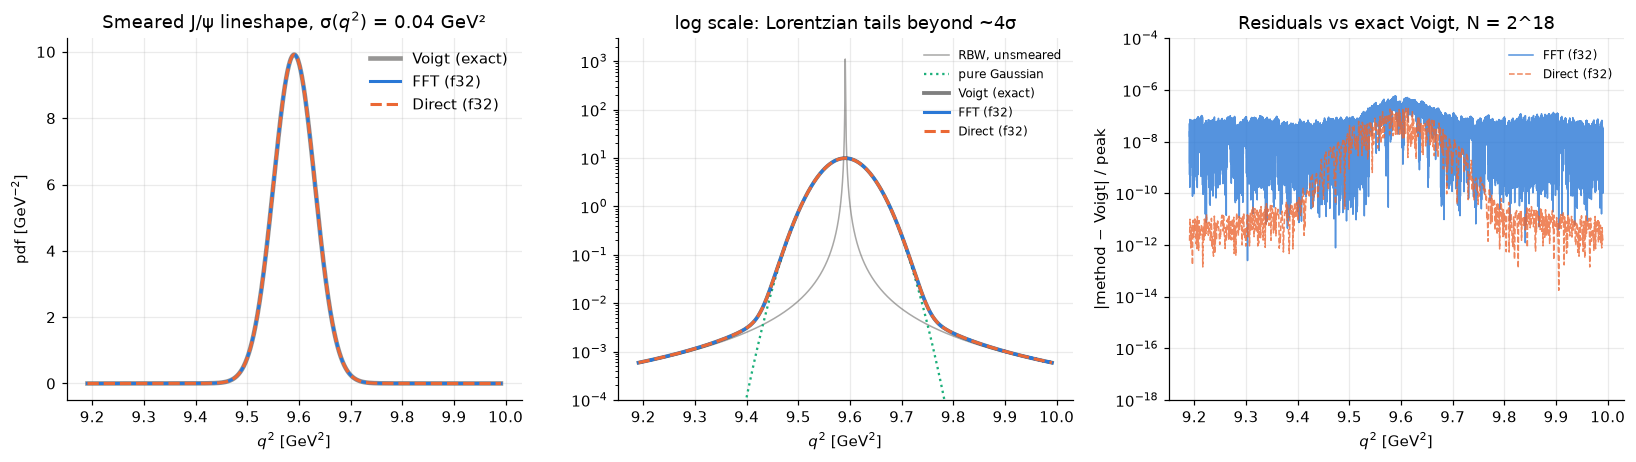

In [41]:
C = {"ref": "#52514e", "fft": "#2a78d6", "direct": "#eb6834", "aqua": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False, "font.size": 10})
LS = {"fft": "-", "direct": "--"}
NAME = {"fft": f"FFT ({DTYPE})", "direct": f"Direct ({DTYPE})"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
xq = X_OUT + M2
ax = axes[0]                                              # (a) linear scale
ax.plot(xq, REF_OUT, color=C["ref"], lw=3, alpha=0.6, label="Voigt (exact)")
for m, (xx, yy) in curves.items():
    ax.plot(xx + M2, yy, color=C[m], lw=2, ls=LS[m], label=NAME[m])
ax.set_xlabel("$q^2$ [GeV$^2$]"); ax.set_ylabel("pdf [GeV$^{-2}$]"); ax.set_title("Smeared J/ψ lineshape, σ($q^2$) = 0.04 GeV²"); ax.legend()
ax = axes[1]                                              # (b) log scale incl. unsmeared RBW
x_plot, _ = make_grid(N_PLOT); w = (x_plot > -0.4) & (x_plot < 0.4)
ax.plot(x_plot[w] + M2, rbw_x(x_plot[w]), color=C["ref"], lw=1, alpha=0.5, label="RBW, unsmeared")
ax.plot(xq, gauss(X_OUT), color=C["aqua"], lw=1.5, ls=":", label="pure Gaussian")
ax.plot(xq, REF_OUT, color="k", lw=2.5, alpha=0.5, label="Voigt (exact)")
for m, (xx, yy) in curves.items():
    ax.plot(xx + M2, yy, color=C[m], lw=2, ls=LS[m], label=NAME[m])
ax.set_yscale("log"); ax.set_ylim(1e-4, 3e3); ax.set_xlabel("$q^2$ [GeV$^2$]"); ax.set_title("log scale: Lorentzian tails beyond ~4σ"); ax.legend(fontsize=8)
ax = axes[2]                                              # (c) residuals vs exact
for m, (xx, yy) in curves.items():
    ax.plot(xx + M2, np.abs(yy - voigt_ref(xx)) / PEAK + 1e-18, color=C[m], lw=1, ls=LS[m], alpha=0.8, label=NAME[m])
ax.set_yscale("log"); ax.set_ylim(1e-18, 1e-4); ax.set_xlabel("$q^2$ [GeV$^2$]"); ax.set_ylabel("|method − Voigt| / peak")
ax.set_title(f"Residuals vs exact Voigt, N = 2^{int(np.log2(N_PLOT))}"); ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(f"plots/lineshape_N{int(np.log2(N_PLOT))}_{DTYPE}.png", bbox_inches="tight"); plt.show()

## Timing scan over grid size N

FFT scales as N log N, the direct integral as N_out × N. Accuracy (`max_rel_err` = max |method − Voigt| / peak over the output window) is reported alongside the time.

In [42]:
rows = []
t_start = time.time()
for N in N_LIST:
    for method in ("fft", "direct"):
        r, _ = run_config(method, N)
        rows.append(r)
        print(f"N=2^{int(np.log2(N)):2d} {method:6s} {DTYPE}  t={r['t_median_ms']:10.3f} ms  err={r['max_rel_err']:.2e}  ({r['reps']} reps)")
print(f"scan took {time.time()-t_start:.0f} s")
df = pd.DataFrame(rows)
df.to_csv(f"results/timings_{DTYPE}.csv", index=False)

piv_t = df.pivot_table(index="method", columns="N", values="t_median_ms")
piv_e = df.pivot_table(index="method", columns="N", values="max_rel_err")
piv_t.columns = [f"N=2^{int(np.log2(c))}" for c in piv_t.columns]; piv_e.columns = piv_t.columns
print(f"Median time [ms], GPU {DTYPE}"); display(piv_t.round(3))
print("max |method - Voigt| / peak"); display(piv_e.map(lambda v: f"{v:.1e}"))
with open(f"results/summary_{DTYPE}.md", "w") as f:
    f.write(f"### Median time [ms], TF GPU {DTYPE}\n\n" + piv_t.round(3).to_markdown()
            + "\n\n### max |method − Voigt| / peak\n\n" + piv_e.map(lambda v: f"{v:.1e}").to_markdown() + "\n")

N=2^12 fft    f32  t=     0.802 ms  err=4.90e-02  (20 reps)
N=2^12 direct f32  t=     5.377 ms  err=4.90e-02  (20 reps)
N=2^14 fft    f32  t=     2.541 ms  err=1.20e-06  (20 reps)
N=2^14 direct f32  t=    10.269 ms  err=8.90e-07  (20 reps)
N=2^16 fft    f32  t=     2.450 ms  err=3.93e-07  (20 reps)
N=2^16 direct f32  t=    12.985 ms  err=1.95e-07  (20 reps)
N=2^18 fft    f32  t=     0.741 ms  err=5.82e-07  (20 reps)
N=2^18 direct f32  t=    49.525 ms  err=2.07e-07  (20 reps)
N=2^20 fft    f32  t=     1.624 ms  err=6.84e-07  (20 reps)
N=2^20 direct f32  t=   208.980 ms  err=2.75e-06  (5 reps)
scan took 5 s
Median time [ms], GPU f32


,N=2^12,N=2^14,N=2^16,N=2^18,N=2^20
method,,,,,
direct,5.377,10.269,12.985,49.525,208.980
fft,0.802,2.541,2.450,0.741,1.624


max |method - Voigt| / peak


,N=2^12,N=2^14,N=2^16,N=2^18,N=2^20
method,,,,,
direct,4.9e-02,8.9e-07,1.9e-07,2.1e-07,2.8e-06
fft,4.9e-02,1.2e-06,3.9e-07,5.8e-07,6.8e-07


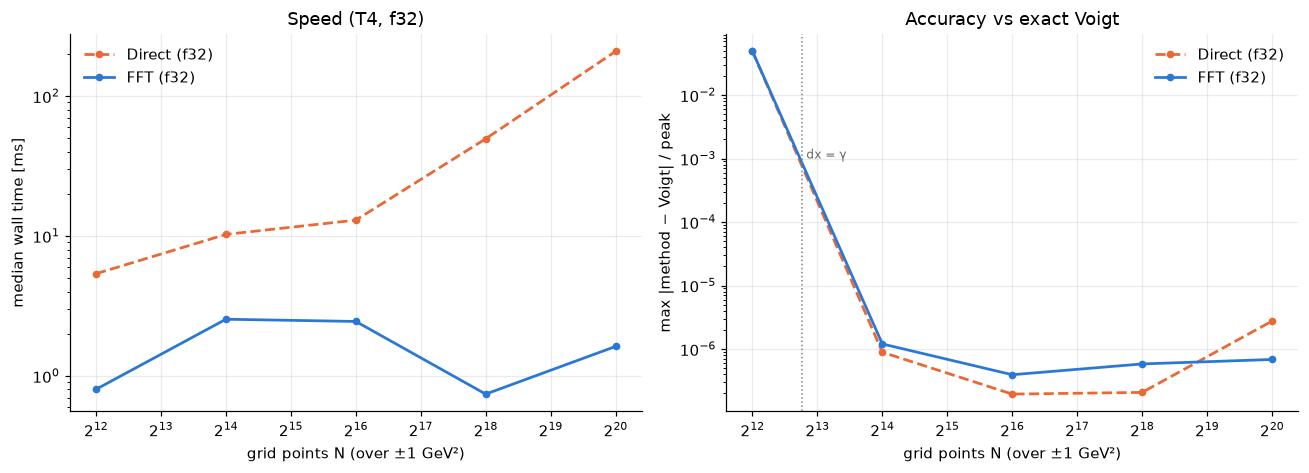

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for m, g in df.groupby("method"):
    axes[0].plot(g.N, g.t_median_ms, color=C[m], ls=LS[m], marker="o", ms=4, lw=1.8, label=NAME[m])
    axes[1].plot(g.N, g.max_rel_err, color=C[m], ls=LS[m], marker="o", ms=4, lw=1.8, label=NAME[m])
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("grid points N (over ±1 GeV²)"); ax.legend()
axes[0].set_ylabel("median wall time [ms]"); axes[0].set_title(f"Speed (T4, {DTYPE})")
axes[1].set_ylabel("max |method − Voigt| / peak"); axes[1].set_title("Accuracy vs exact Voigt")
axes[1].axvline(2*HALF_RANGE/GAMMA_Q2, color="0.5", lw=1, ls=":"); axes[1].text(2*HALF_RANGE/GAMMA_Q2, 1e-3, " dx = γ", color="0.4", fontsize=8)
fig.tight_layout(); fig.savefig(f"plots/timing_scan_{DTYPE}.png", bbox_inches="tight"); plt.show()

## Cost model: direct n_out × N versus FFT N log N

The direct integral costs one kernel evaluation per (output point, grid point) pair, i.e. n_out × N. The FFT costs N log N independent of how many output points are needed afterwards (plus a cheap interpolation). Here n_out = `N_OUT_FIT`, e.g. the number of events in a fit.

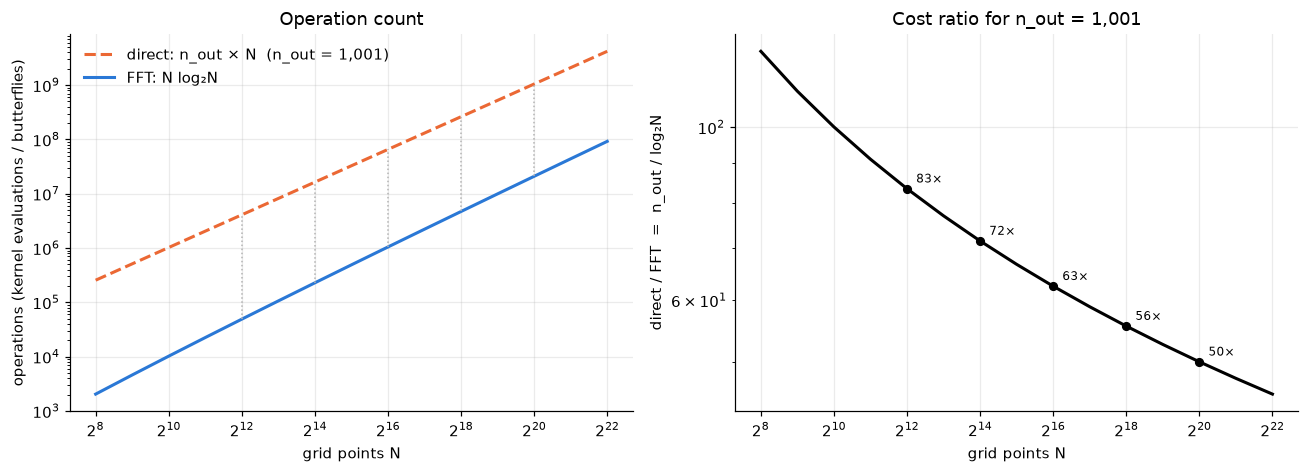

In [44]:
N_OUT_FIT = 1001                             # number of output points (events) assumed in the cost-model plot
Ns = 2.0 ** np.arange(8, 23)
ops_direct = N_OUT_FIT * Ns
ops_fft    = Ns * np.log2(Ns)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
ax.plot(Ns, ops_direct, color=C["direct"], ls=LS["direct"], lw=2, label=f"direct: n_out × N  (n_out = {N_OUT_FIT:,})")
ax.plot(Ns, ops_fft,    color=C["fft"],    ls=LS["fft"],    lw=2, label="FFT: N log₂N")
for N in N_LIST:                                       # mark the grid sizes used in the timing scan
    ax.plot([N, N], [N*np.log2(N), N_OUT_FIT*N], color="0.7", lw=1, ls=":")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("grid points N"); ax.set_ylabel("operations (kernel evaluations / butterflies)")
ax.set_title("Operation count"); ax.legend(loc="upper left")
ax = axes[1]
ax.plot(Ns, ops_direct / ops_fft, color="k", lw=2)
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("grid points N"); ax.set_ylabel("direct / FFT  =  n_out / log₂N")
ax.set_title(f"Cost ratio for n_out = {N_OUT_FIT:,}")
for N in N_LIST:
    r = N_OUT_FIT / np.log2(N); ax.plot(N, r, "o", color="k", ms=5); ax.annotate(f"{r:,.0f}×", (N, r), textcoords="offset points", xytext=(6, 4), fontsize=8)
fig.tight_layout(); fig.savefig("plots/cost_model.png", bbox_inches="tight"); plt.show()

## Coarse grids: point-sampled vs bin-integrated RBW

When dx ≳ γ the point-sampled Lorentzian is badly integrated by either method. Replacing the sample by the **bin-averaged** RBW (analytic arctan integral over each bin) fixes this at zero extra cost, so small N becomes usable.

In [45]:
rows2 = []
for N in [2**k for k in (8, 10, 12, 14, 16)]:
    for bi in (False, True):
        for method in ("fft", "direct"):
            rows2.append(run_config(method, N, bin_integrated=bi)[0])
p = pd.DataFrame(rows2).pivot_table(index=["method", "bin_integrated"], columns="N", values="max_rel_err")
p.columns = [f"N=2^{int(np.log2(c))}" for c in p.columns]
print(f"max |method - Voigt| / peak, GPU {DTYPE}:"); display(p.map(lambda v: f"{v:.1e}"))
with open(f"results/summary_{DTYPE}.md", "a") as f:
    f.write(f"\n### Bin-integrated vs point-sampled RBW (TF GPU {DTYPE}), max rel err\n\n" + p.map(lambda v: f"{v:.1e}").to_markdown() + "\n")

max |method - Voigt| / peak, GPU f32:


N=2^8   N=2^10   N=2^12   N=2^14   N=2^16
method bin_integrated                                             
direct False           8.9e-01  5.7e-01  4.9e-02  8.9e-07  1.9e-07
       True            4.3e-03  2.1e-04  7.1e-06  5.1e-07  2.3e-07
fft    False           8.9e-01  5.7e-01  4.9e-02  1.2e-06  3.9e-07
       True            4.3e-03  2.1e-04  7.4e-06  8.0e-07  3.8e-07

## Notes

* Domain truncation: ~10⁻⁴ of the Lorentzian normalisation lies outside the ±1 GeV² grid, but it sits ≥ 15σ from the ±0.4 GeV² output window, so after smearing its effect there is negligible (f64 agrees with the Voigt profile to ~10⁻¹⁵).
* Grid resolution: with point-sampled RBW the error is 5 % at N = 2¹² (dx ≈ 1.7γ), 10⁻⁶ at N = 2¹⁴ (dx ≈ 0.4γ) and machine precision from N = 2¹⁶ (dx ≈ 0.1γ). With the bin-integrated RBW, N = 2¹² already gives 10⁻⁵.
* T4 GPUs have 1/32-rate float64; set `DTYPE = "f32"` at the top to see the precision/speed trade-off (FFT f32 reaches ~5×10⁻⁷ of peak).
* The direct cost is proportional to N_out (1001 here); in a fit evaluated at many events it scales with the number of events, whereas the FFT cost is fixed per PDF evaluation plus an interpolation.